<a href="https://colab.research.google.com/github/derekhatherley/A04-clustering/blob/main/A4_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

Q1-1: Run the code below

In [1]:
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

As noise increases, the visual distinctness of the data clusters decreases. Higher noise levels induced overlap of points in each cluster, while lower noise levels had distinct clusters of points, with the lowest noise corresponding to the tightest clusters.

Q2-2: Make scatterplots

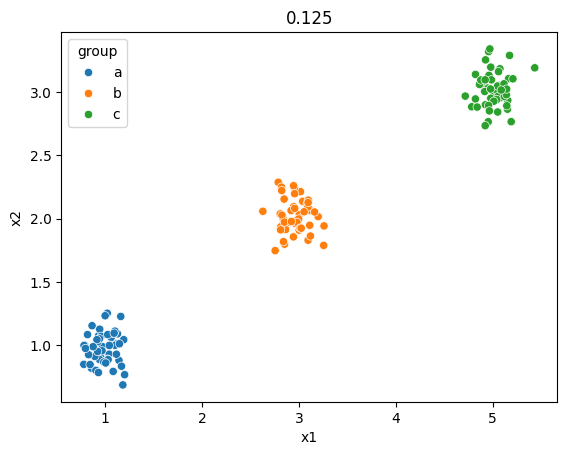

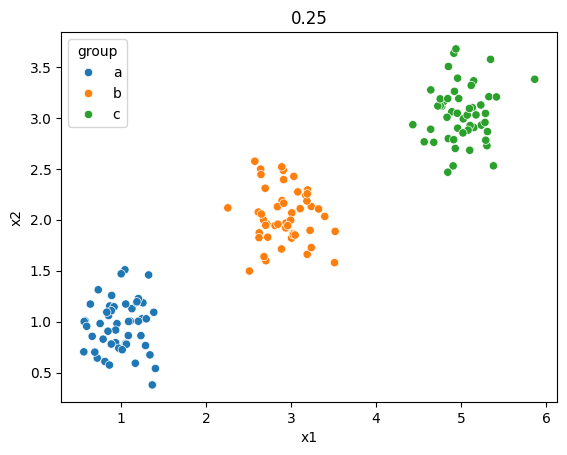

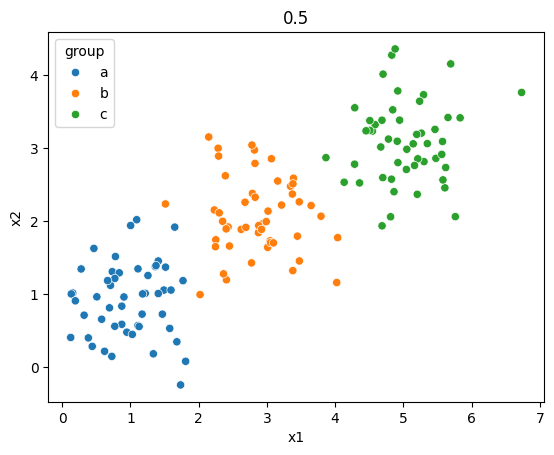

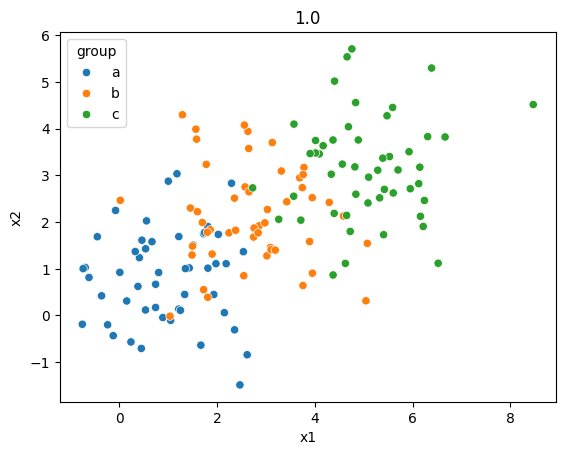

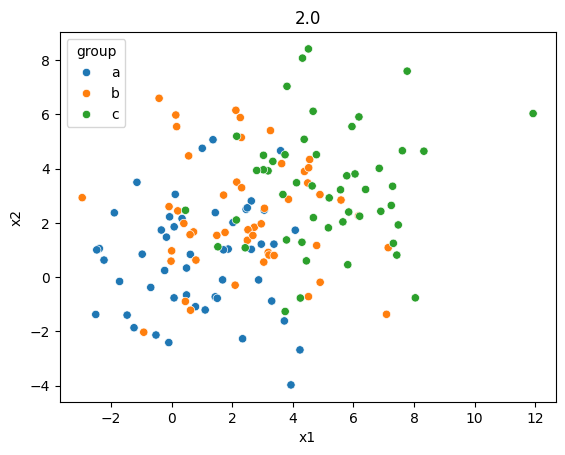

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.scatterplot(data=df0_125, x='x1', y='x2', hue='group')
plt.title('0.125')
plt.show()
print()
sns.scatterplot(data=df0_25, x='x1', y='x2', hue='group')
plt.title('0.25')
plt.show()
print()
sns.scatterplot(data=df0_5, x='x1', y='x2', hue='group')
plt.title('0.5')
plt.show()
print()
sns.scatterplot(data=df1_0, x='x1', y='x2', hue='group')
plt.title('1.0')
plt.show()
print()
sns.scatterplot(data=df2_0, x='x1', y='x2', hue='group')
plt.title('2.0')
plt.show()


Q1-3: Create a scree plot for each of the datasets

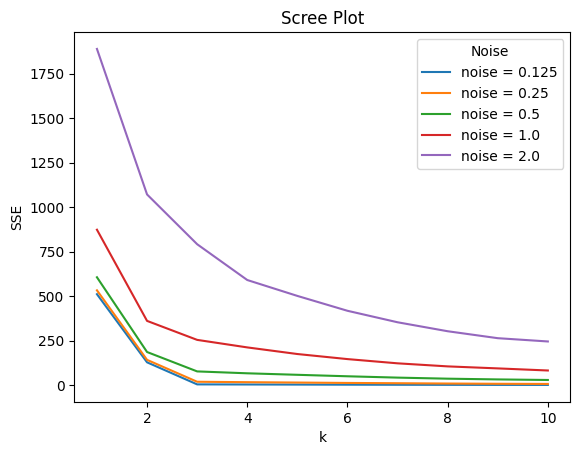

In [3]:
from sklearn.cluster import KMeans

ks = np.arange(1,11)
# datasets dictionary to be able to iterate onto one graph
datasets = {'0.125': df0_125, '0.25': df0_25, '0.5': df0_5, '1.0': df1_0, '2.0': df2_0}
for noise, df in datasets.items():
  X = df[['x1', 'x2']]
  SSE = [
      KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
      .fit(X).inertia_
      for k in ks
  ]
# Making a scree plot as shown in slides
  sns.lineplot(x=ks, y=SSE, label=f'noise = {noise}').set(title="Scree Plot", xlabel="k", ylabel="SSE")
# add legend on the graph
plt.legend(title='Noise')
plt.show()


High noise levels caused the elbow at lower noise levels (like 0.125) to become less less pronounced. For the 3 lowest noise levels, there is a clear elbow at k=3. However, as noise increases to 1 or 2, that elbow is essentially flattened, and there isn't as clear of a k at an elbow to definitively select. Higher noise levels also caused the SSE values for the entire plot to increase, essentially shifting the graph upwards relative to lower noise values, with a less distinct elbow.

Q1-4: Explain the intuition of the elbow, using this numerical simulation as an example.

SSE will always decrease as k increases. However, the optimal k, which is located at the elbow, represents the real number of groups. In this example, the lower noise graphs clearly have 3 clusters, so it makes sense that there is an elbow at k=3. For the higher noise graphs, it is much harder to eyeball there being 3 distinct groups, and the scree plot emphasizes that by not showing a clear elbow at the same k as the lower noise values. Any k value less than 3 for one of the low noise datasets would represent too few groups, greatly increasing the SSE. A k over 3 would only decrease the SSE minimally, since a k=3 represents the 3 clusters and increasing k will only split those clusters.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Derek Hatherley

**Date:**

Q2-1: Cleaning

In [4]:
df = pd.read_csv('SIPRI Military Expenditure Database.csv')
df = df.copy()
df = df[df['Year'] == 2020]
missing = df.isna().sum()
print(missing)
# Missing data, going to drop rows instead of filling
df = df.dropna()
print(df.dtypes) # data types are clean
print(df.shape) # dealing with 148 rows now
df
# no further cleaning required now


index                              0
Year                               0
Country                            0
Spending (2020 USD)               23
Percent of GDP                    23
Percent of Government Spending    25
Spending per Capita               24
dtype: int64
index                               int64
Year                                int64
Country                            object
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object
(148, 7)


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731
...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514


Q2-2: Max-min normalize Spending (2020 USD) and Spending per Capita. Use a scree plot to determine the optimal number of clusters for the  𝑘  means clustering algorithm. Make a scatter plot of Spending (2020 USD) and Spending per Capita, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. .groupby(cluster).describe()). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?

In [5]:
# Max-min normalize as shown in slides
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


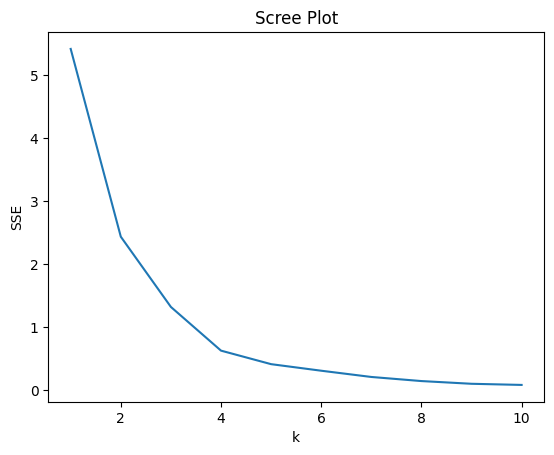

In [6]:
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title = 'Scree Plot', xlabel = 'k', ylabel = 'SSE')
plt.show()
# Optimal k is 3

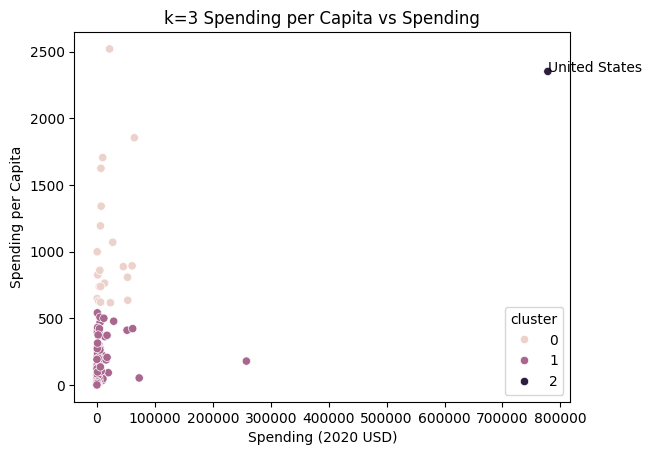

index                                                            \
         count         mean          std     min     25%     50%     75%   
cluster                                                                    
0         21.0  2913.904762  1632.102874   236.0  1834.0  2922.0  4044.0   
1        126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
2          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
cluster                         ...                                            
0        5506.0   21.0  2020.0  ...                       0.110270  0.225050   
1        5880.0  126.0  2020.0  ...                       0.077917  0.303027   
2        5540.0    1.0  2020.0  ...                       0.081976  0.081976   

        Spending per Capita                                        \
                      count         mean         std          min   
cluster                                                             
0                      21.0  1046.433509  501.631845   616.854430   
1                     126.0   122.034996  140.041183     0.580129   
2                       1.0  2351.631858         NaN  2351.631858   

                                                             
                 25%          50%          75%          max  
cluster                                                      
0         737.690186   859.880548  1193.598730  2520.398541  
1          18.505805    58.809109   188.249364   541.154778  
2        2351.631858  2351.631858  2351.631858  2351.631858  

[3 rows x 48 columns]

In [7]:
k = 3
model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_
us = df[df['Country'] == 'United States of America']

sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='cluster')
plt.title('k=3 Spending per Capita vs Spending')
plt.annotate('United States', (us['Spending (2020 USD)'].iloc[0], us['Spending per Capita'].iloc[0]))
plt.show()

df.groupby('cluster').describe()

Of the 148 rows, 147 of them lie on the left half of the x axis. Only the United States lies in the top right-hand corner of the graph, and it makes up cluster 2 itself. The vast majority of the countries lie in cluster 1, which is in the lower left-hand side of the graph. Cluster 0 takes up the rest of the left side of the graph, with less countries and a slightly larger range of spending per capita (y axis) values relative to cluster 1. Since the difference between cluster 1 and 0 is spending per capita, there seems to be a pattern of placement in the cluster based on the wealth of the country. However, the US is obviously a huge outlier with its own cluster.

Q2-3: Repeat part 2 for Percent of Government Spending and Percent of GDP. How do your results compare to part 2?

In [8]:
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


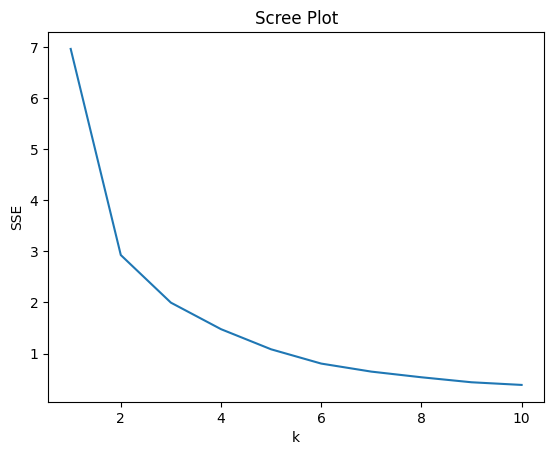

In [9]:
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title = 'Scree Plot', xlabel = 'k', ylabel = 'SSE')
plt.show()
# Much less distinct elbow. Picking k=3 but could also see k=2 or k=6 as reasonable

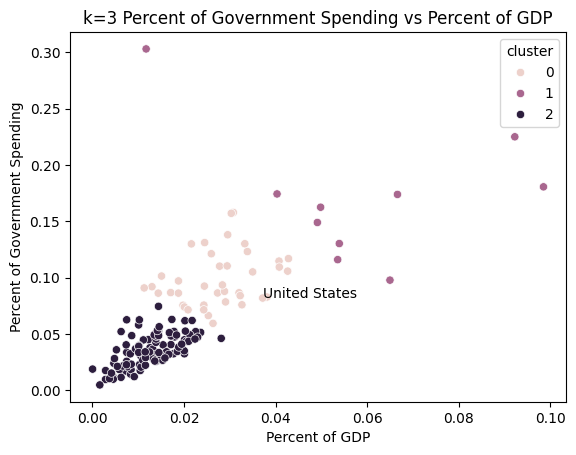

index                                                           \
        count         mean          std    min     25%     50%     75%   
cluster                                                                  
0        39.0  2894.974359  1789.517893  338.0  1052.0  2854.0  4741.0   
1        10.0  2184.200000  1773.299110  100.0   329.5  2650.0  3763.5   
2        99.0  2871.515152  1590.144034   32.0  1647.0  2956.0  4197.0   

                 Year          ... Percent of Government Spending            \
            max count    mean  ...                            75%       max   
cluster                        ...                                            
0        5540.0  39.0  2020.0  ...                       0.112633  0.157918   
1        4486.0  10.0  2020.0  ...                       0.179081  0.303027   
2        5880.0  99.0  2020.0  ...                       0.047402  0.074624   

        Spending per Capita                                                 \
                      count        mean         std        min         25%   
cluster                                                                      
0                      39.0  271.264618  484.849023   5.674383   24.603244   
1                      10.0  817.301890  904.866469  47.056944  204.615548   
2                      99.0  211.624304  278.496227   0.580129   16.487333   

                                               
                50%          75%          max  
cluster                                        
0        115.732975   209.705770  2351.631858  
1        221.050502  1517.266870  2520.398541  
2         72.164472   367.649743  1341.058851  

[3 rows x 48 columns]

In [10]:
k = 3
model = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model.labels_

sns.scatterplot(data=df, x='Percent of GDP', y='Percent of Government Spending', hue='cluster')
plt.title('k=3 Percent of Government Spending vs Percent of GDP')
plt.annotate('United States', (us['Percent of GDP'].iloc[0], us['Percent of Government Spending'].iloc[0]))
plt.show()

df.groupby('cluster').describe()

These results are pretty different, especially looking at the United States. The outlier that they are in terms of total spending is less dramatic as a percent of their GDP and total government spending. Instead, they are right in the thick of cluster 0, which has 38 other countries in it. This model is more interesting in terms of selecting the proper k value. There are a few k values with k values that could be selected based on the scree plot. I chose k=3 because there is still a large drop in SSE after the sharpest elbow at k=2. This approach seems to identify 2 major clusters, with a third consisting of some of the points furthest ton the upper right-hand portion of the plot.

Q2-4: Use  𝑘  means clustering with all four numeric variables: Spending (2020 USD), Spending per Capita, Percent of Government Spending, and Percent of GDP. How do your results compare to the previous two parts?

In [11]:
features = ["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP",]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


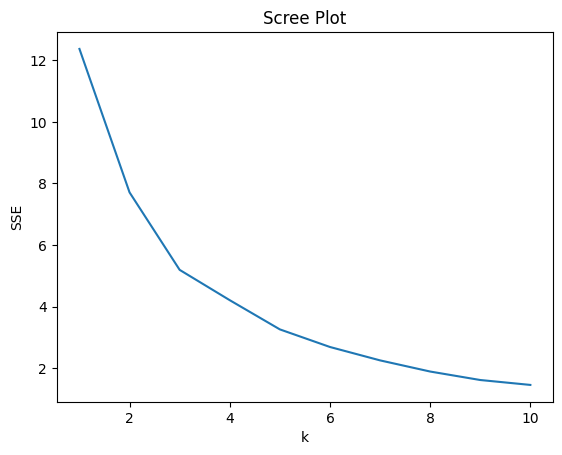

In [12]:
ks = np.arange(1,11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title = 'Scree Plot', xlabel = 'k', ylabel = 'SSE')
plt.show()
# No real clear elbow
# Will pick best k based on plots produced

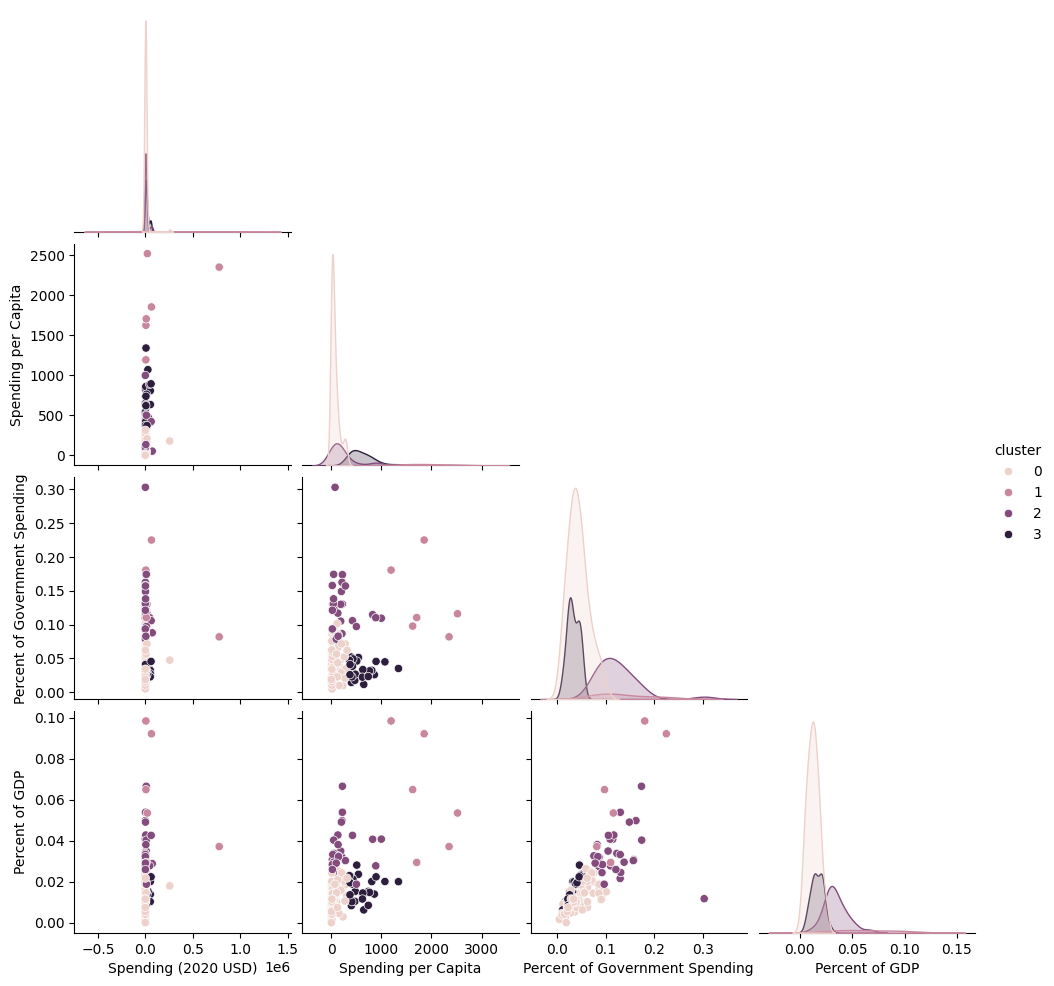

cluster                                           0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                               50%        34.845855    1780.059564   
                               75%        95.985387    2227.318999   
                               max       314.201312    2520.398541   
Percent of Government Spending count      86.000000       6.000000   
                               mean        0.043199       0.135351   
                               std         0.021512       0.055392   
                               min         0.004896       0.081976   
                               25%         0.028414       0.101034   
                               50%         0.040096       0.113271   
                               75%         0.053006       0.164503   
                               max         0.101501       0.225050   
Percent of GDP                 count      86.000000       6.000000   
                               mean        0.012481       0.062634   
                               std         0.005799       0.028275   
                               min         0.000054       0.029429   
                               25%         0.007811       0.041272   
                               50%         0.012532       0.059257   
                               75%         0.016783       0.085398   
                               max         0.026340       0.098470   

cluster                                          2             3  
Spending (2020 USD)            count     30.000000     26.000000  
                               mean    9073.543709  15330.618681  
                               std    18135.032885  18923.469359  
                               min      163.926877    405.790494  
                               25%      522.737081   3176.345598  
                               50%     1663.090134   5857.060906  
                               75%     8646.648849  21818.934764  
                               max    72937.064048  60675.039625  
Spending per Capita            count     30.000000     26.000000  
                               mean     215.920971    612.677541  
                               std      261.610456    241.189507  
                               min       18.297119    362.467076  
                               25%       46.200403    413.682029  
                               50%      137.955585    579.004604  
                               75%      219.021206    738.120108  
                               max      998.966186   1341.058851  
Percent of Government Spending count     30.000000     26.000000  
                               mean       0.123701      0.033280  
                               std        0.044494      0.011771  
                               min        0.076005      0.011613  
                               25%        0.092832      0.026028  
                               50%        0.115883      0.032077  
                               75%        0.136403      0.044645  
                               max        0.303027      0.052209  
Percent of GDP

In [15]:
k = 4
model_all = KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0).fit(X)
df['cluster'] = model_all.labels_
# doing a pairplot to see every variable agaisnt every other variable
sns.pairplot(df, vars=features, hue='cluster', corner=True)
plt.show()
df.groupby('cluster')[features].describe().T
# Transpose for readability

On the scree plot, there is no sharp elbow, so I chose a k value based on the plots I produced later. It could be reasonable to choose a k of 3 or 5, or whatever someone deemed as best in their opinion. The resulting plots are far more difficult to interpret as comapred to 2-variable comparisons. This analysis has the advantage of looking at all metrics that contextualize each other. For example, total spending isn't useful without also considering the percent of government spending or indicators of economic strength via % of GDP and spending per capita. Compared to the previous 2 parts, there is much more overlap between clusters. However, they largely remain consistent across all graphs, despite having to develop a relationship between 4 columns.

Q2-5: Did the  𝑘 -MC algorithm find any useful patterns for you in analyzing the spending?

I think that the most useful pattern revealed by analyzing spending is that clusters tend to be relatively consistent, meaning countries were generally high or low or somewhere in between across all 4 columns. It is also important to takeaway that each of the columns represent different things that can may correlate, but in isolation one can make certain countries look like outliers. In total spending, the United States was far and away the highest, but in the context of the other 3 categories, it sat in the same cluster as other high spending countries. Despite there being some value in the patterns produced, the lack of clear elbows on the scree curves helps to suggest that these are not clean, descrete clusters. The patterns produced may be a suitable starting point for analyzing spending, but they do not tell the complete story or produce any concrete answers.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [14]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]